In [17]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from helper.quantumScarFunctions import *
from helper.quantumScarsPlotting import *

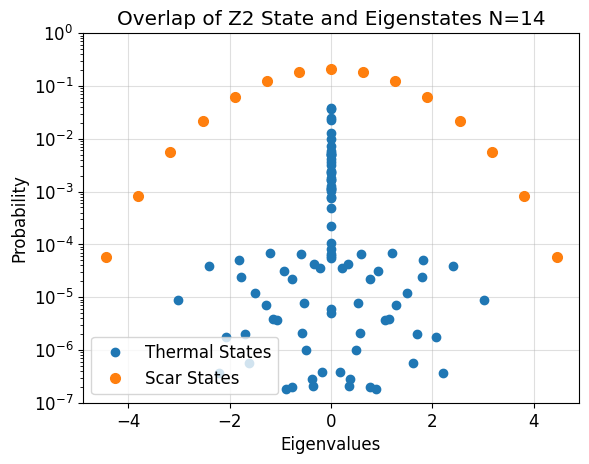

In [18]:
N = 14

H0, eigenvalues, eigenstates, psi0, basisList = get_scar_ham(N)
H1, driveWeights = get_scar_H1(N, basisList)
zero_scar, z2_overlap = get_zero_scar(N)

# find scar indices using overlaps
sections = np.linspace(eigenvalues[0] - 0.5, eigenvalues[-1] + 0.5, N+2)
scarIndices = []
scarStates = []

for i in range(len(sections) - 1):

    eigenSection = []

    for k in range(len(eigenvalues)):
        if (eigenvalues[k] > sections[i]) and (eigenvalues[k] < sections[i+1]):
            eigenSection.append(k)

    highestOverlap = np.abs(psi0.dag() * eigenstates[eigenSection[0]]) ** 2
    highestOverlapIndex = eigenSection[0]

    if len(eigenSection) == 1:
        scarIndices.append(eigenSection[0])
        continue
        
    for m in range(1, len(eigenSection)):
        if np.abs(psi0.dag() * eigenstates[eigenSection[m]]) ** 2 > highestOverlap:
            highestOverlap = np.abs(psi0.dag() * eigenstates[eigenSection[m]]) ** 2
            highestOverlapIndex = eigenSection[m]
    
    scarIndices.append(highestOverlapIndex)

scarStates = [eigenstates[i] for i in scarIndices]
scarStates[len(scarIndices) // 2] = zero_scar # sets zero energy scar state to S2 one

amplitudes = []
eigenvalueIndices = []

for i in scarIndices:
    amplitudes.append(psi0.dag() * eigenstates[i])
    eigenvalueIndices.append(eigenvalues[i])

amplitudes2 = []
for states in eigenstates:
    amplitudes2.append(psi0.dag() * states)

plt.plot(eigenvalues, np.abs(amplitudes2) ** 2, ".", ms=12, label="Thermal States")
plt.yscale("log")
plt.xlabel("Eigenvalues")
plt.ylabel("Probability")
plt.grid(True, alpha=0.4)
plt.ylim(10**-7, 1)
plt.title(f"Overlap of Z2 State and Eigenstates N={N}")

amplitudes[len(amplitudes)//2] = psi0.dag() * zero_scar
plt.plot(eigenvalueIndices, np.abs(amplitudes) ** 2, ".", ms=14, label="Scar States")

plt.legend()
plt.savefig(f"scar_arc_N{N}.pdf")
plt.show()